<a href="https://colab.research.google.com/github/Krzyker/DataScienceColabs/blob/main/cse351_hw3_brachowski_krzysztof_116565000.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **New York City AirBnB Data Analysis Project**

Krzysztof Brachowski

---
This assignment uses data available at [this kaggle repository](https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data).

In [6]:
#imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#reading in the data
data = pd.read_csv('/content/AB_NYC_2019.csv')
data.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


Using the describe() function, I notice some anomalies in the data that should be cleaned up. For example, there is an AirBnB with a minmum_nights value of 1250. There are also listings with a price value of 0. I will utilize seaborn functions to plot data and spot anomalies easier.

<Axes: xlabel='minimum_nights'>

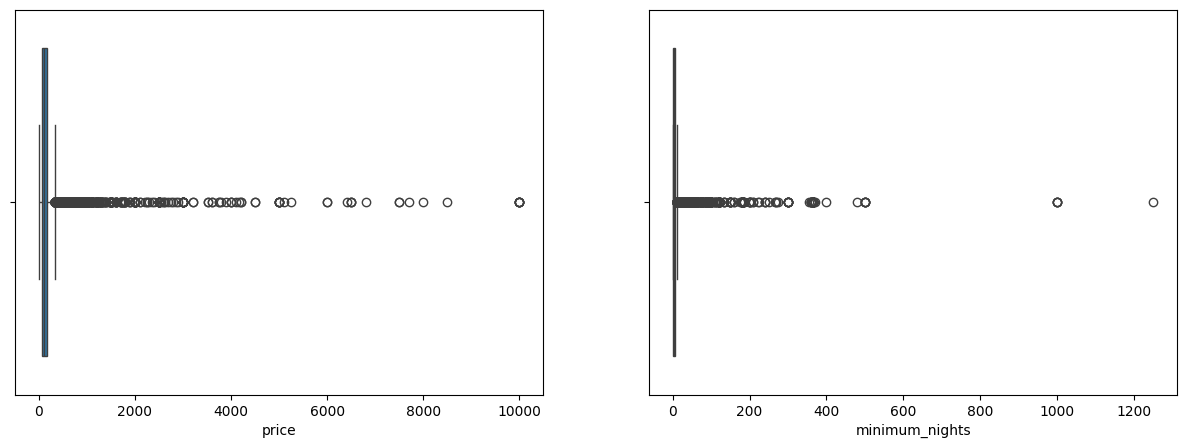

In [7]:
fix, axes = plt.subplots(1, 2, figsize = (15,5)) #using matplotlib to display charts side by side

# unedited data charts
sns.boxplot(x=data['price'], ax = axes[0])
sns.boxplot(x=data['minimum_nights'], ax = axes[1])

For the purposes of this data analysis, I will get rid of data with a minimum price of 0, and data with minimum_nights greater than 100. Importantly, I am not adressing the extreme outliers in price, since I believe they will have important bearing on price difference per neighbourhood.

                 id       host_id      latitude     longitude         price  \
count  4.871000e+04  4.871000e+04  48710.000000  48710.000000  48710.000000   
mean   1.902923e+07  6.768092e+07     40.728926    -73.952116    152.337323   
std    1.097921e+07  7.863728e+07      0.054537      0.046189    237.261250   
min    2.539000e+03  2.438000e+03     40.499790    -74.244420     10.000000   
25%    9.477162e+06  7.835312e+06     40.690060    -73.983030     69.000000   
50%    1.969462e+07  3.085086e+07     40.723040    -73.955660    106.000000   
75%    2.915608e+07  1.074344e+08     40.763130    -73.936170    175.000000   
max    3.648724e+07  2.743213e+08     40.913060    -73.712990  10000.000000   

       minimum_nights  number_of_reviews  reviews_per_month  \
count    48710.000000       48710.000000       38744.000000   
mean         6.155471          23.317430           1.375268   
std         10.049833          44.573394           1.681299   
min          1.000000           0.00

<Axes: xlabel='minimum_nights'>

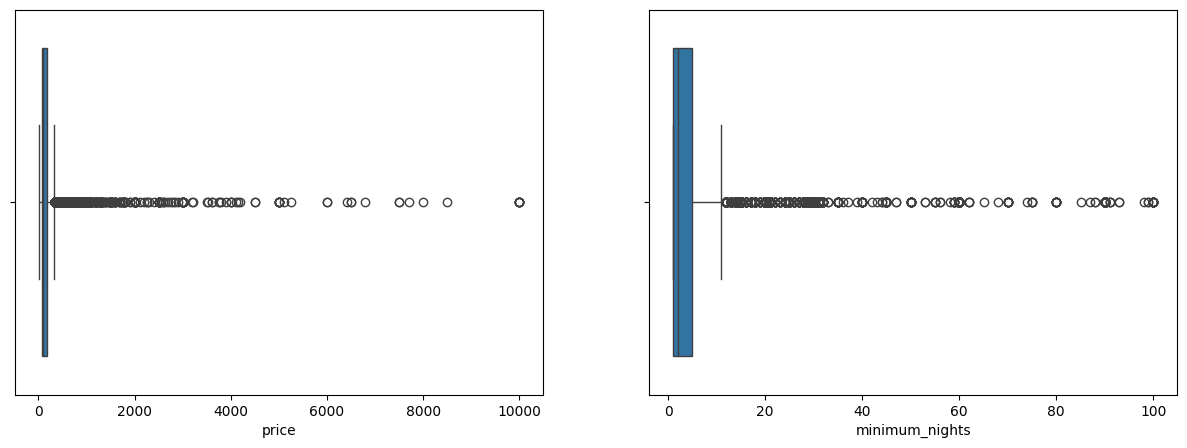

In [8]:
data = data[data['price'] > 0]
data = data[data['minimum_nights'] <= 100]
data.reset_index() # brings back sequential indexing by patching holes

#re-displaying
print(data.describe())
fix, axes = plt.subplots(1, 2, figsize = (15,5))
sns.boxplot(x=data['price'], ax = axes[0])
sns.boxplot(x=data['minimum_nights'], ax = axes[1])

# **Neighbourhood Analysis**
---
We will examine how the prices of AirBnBs change with change in neighbourhood. Out of neighbourhoods with over 5 listings, we will find the top 5 and bottom 5 neighborhoods by median AirBnB price.

In [9]:
# calculating medians
medians = data.groupby('neighbourhood')['price'].median()